# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in `Samoa.json`).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.offshore_waves import boundary_parameters
from utils.snapwave_wrapper import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in Samoa.json → offshore_waves
period = "2020-05"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/WHACS/processed/Samoa_WHACS.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-dynamic
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
period    : 2020-05


## Offshore waves → boundary forcing

In [3]:
import xarray as xr

offshore_ds = xr.concat(
    [
        open_offshore_waves(entry=offshore_entry).sel(time=slice("1989-09", "1990-04")),
        open_offshore_waves(entry=offshore_entry).sel(time="2020"),
    ],
    dim="time",
).load()
offshore_ds

<xarray.Dataset> Size: 26MB
Dimensions:   (time: 14592, goal: 11)
Coordinates:
  * time      (time) datetime64[ns] 117kB 1989-09-01 ... 2020-12-31T23:00:00
  * goal      (goal) int64 88B 1 2 3 4 5 6 7 8 9 10 11
    seapoint  (goal) int64 88B 971044 971049 970816 ... 969776 970007 970465
Data variables: (12/20)
    dir       (time, goal) float64 1MB 104.3 95.7 96.4 ... 167.7 195.5 15.1
    hs        (time, goal) float64 1MB 2.006 1.93 1.938 ... 1.138 1.066 1.344
    pdir0     (time, goal) float64 1MB 86.6 94.2 94.0 98.4 ... nan nan 93.8 nan
    pdir1     (time, goal) float64 1MB 215.8 220.4 143.7 ... 63.4 191.3 35.6
    pdir2     (time, goal) float64 1MB 169.5 107.3 216.7 ... 191.2 219.7 215.3
    pdir3     (time, goal) float64 1MB 165.2 289.3 109.2 ... 220.3 186.4 347.8
    ...        ...
    ptp0      (time, goal) float64 1MB 7.4 7.4 7.37 7.3 ... nan nan 8.33 nan
    ptp1      (time, goal) float64 1MB 13.71 13.72 11.27 ... 7.81 12.09 8.03
    ptp2      (time, goal) float64 1MB 5.96 16.29 13.65 ... 12.12 11.52 11.47
    ptp3      (time, goal) float64 1MB 11.11 14.92 16.56 ... 11.46 7.02 11.02
    spr       (time, goal) float64 1MB 48.3 33.4 33.9 35.0 ... 62.4 59.0 66.9
    tp        (time, goal) float64 1MB 7.407 7.407 7.353 ... 12.05 11.76 11.24
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

## SnapWave wrapper

In [5]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-06-30 12:12:24,597 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-06-30 12:12:24,598 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-06-30 12:12:24,598 - SnapWaveDynamicModelWrapper - WARNING - Parameter dir_goals is not in the default_parameters
2026-06-30 12:12:24,598 - SnapWaveDynamicModelWrapper - WARNING - Parameter spr_goals is not in the default_parameters
2026-06-30 12:12:24,599 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


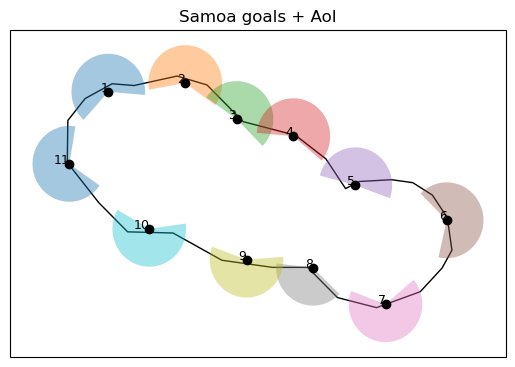

In [6]:
wrapper.plot_configuration()

In [7]:
# wrapper.output_sites_df.to_csv("output_sites.csv")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
# wrapper.run_cases_in_background(launcher="default", num_workers=1)

In [10]:
wrapper.monitor_cases(value_counts="simple")

Status     
FINISHED       9305
NOT STARTED    5286
RUNNING           1
Name: count, dtype: int64

In [11]:
result = wrapper.postprocess_cases()
# out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_198909_199004_2020.nc"
result.to_netcdf(out_nc)

2026-06-30 12:13:14,841 - SnapWaveDynamicModelWrapper - ERROR - Output not postprocessed for case 8562. Error: [Errno 2] No such file or directory: '/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/20200424 180000/output_sites.nc'.
2026-06-30 12:13:14,841 - SnapWaveDynamicModelWrapper - ERROR - Output not postprocessed for case 8563. Error: [Errno 2] No such file or directory: '/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/20200424 190000/output_sites.nc'.
2026-06-30 12:13:14,842 - SnapWaveDynamicModelWrapper - ERROR - Output not postprocessed for case 8564. Error: [Errno 2] No such file or directory: '/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/20200424 200000/output_sites.nc'.
2026-06-30 12:13:14,843 - SnapWaveDynamicModelWrapper - ERROR - Output not postprocessed for case 8565. Error: [Errno 2] No such file or directory: '/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/20200424 210000/output_sites.nc'.
2026

In [12]:
out_nc

PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_198909_199004_2020.nc')

In [13]:
import xarray as xr

xr.open_dataset(out_nc)

<xarray.Dataset> Size: 65MB
Dimensions:         (time: 8561, sites: 631)
Coordinates:
  * time            (time) datetime64[ns] 68kB 1989-09-01 ... 2020-04-24T16:0...
  * sites           (sites) <U24 61kB '5m_0' '5m_1' ... 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 18kB ...
    site_label      (sites) <U5 13kB ...
    site_depth      (sites) float64 5kB ...
    site_longitude  (sites) float64 5kB ...
    site_latitude   (sites) float64 5kB ...
Data variables:
    hs              (time, sites) float32 22MB ...
    tp              (time, sites) float32 22MB ...
    dir             (time, sites) float32 22MB ...
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output